In [20]:
import pandas as pd
import matplotlib.pyplot as plt
from plotnine import *
from sklearn.preprocessing import StandardScaler

import os
os.chdir("C:/Users/alisa/phd/FAP")

## Introduction
This notebook generates a single dataframe for metabolite data produced from SCFA and untargeted metabolomics.

The normalization steps (log transformation and scaling into zero-mean unit variance) is based on the approach in E. Muller et.al Microbiome 2021 [link](https://pmc.ncbi.nlm.nih.gov/articles/PMC8507343/#Sec8)
## Data import
### Sample and compound metadata

In [3]:
# Map metabolomics ID (ms_omics_id) to sample ID (case_number)
sample_mdata = pd.read_excel("metabolomics/RQ00902_r1v1_metadata.xlsx", sheet_name='Sheet1', usecols=[1, 3])
sample_mdata.columns = ["ms_omics_id", "case_number"]
sample_mdata.head()

,ms_omics_id,case_number
0,SA068443,36161549
1,SA068444,35727911
2,SA068445,35956773
3,SA068446,36532014
4,SA068447,36531969


In [6]:
# Import compound names and classes
metabolite_path = "metabolomics/RQ00902_r1v1_profiling_results.xlsx"
compound_names = pd.read_excel(metabolite_path, sheet_name='Compound information', usecols=[0, 3, 10])
compound_names.columns = ["compound_id", "compound_name", "compound_class"]
compound_names.columns = compound_names.columns.str.lower().str.replace(r"\s|-", "_", regex=True)

### Untargeted and SCFA peak area data
#### Untargeted metabolites

In [7]:
# Untargeted metabolomic data import
df = pd.read_excel(metabolite_path, sheet_name='Core data')
df.rename(columns={"MS-Omics ID": "ms_omics_id"}, inplace=True)
df.head()

,ms_omics_id,X01338,X07743,X01951,X01913,X10955,X00159,X00831,X02962,X00686,...,SL00114,SL00158,X00789,SL00108,SL00383,X06324,SL00387,SL00279,X00354,SL00019
0,SA068443,9.781095e+06,200873.036412,2.056731e+05,2.519720e+06,49929.858413,8.427505e+05,2.731288e+06,2.529202e+06,1.539361e+06,...,881540.0,791.664086,16529.921650,38180,79.000000,3.326888e+04,3092.578993,19774.000000,1.601786e+06,27480
1,SA068444,1.174163e+07,882415.917374,7.754979e+04,1.079261e+07,23625.331790,4.680107e+06,4.566922e+05,1.787883e+07,7.594814e+07,...,1100019.0,2973.567004,17931.253268,3668163,115203.000000,4.421128e+04,3145.508846,54222.000000,1.925712e+06,31865
2,SA068445,1.416007e+07,917943.635249,6.970023e+05,3.367708e+06,347409.856359,3.016886e+07,1.176024e+06,5.238853e+05,5.233432e+05,...,92174.0,23436.000000,491276.870770,660058,15779.000000,4.206798e+04,2591.440484,93383.000000,1.658812e+07,136827
3,SA068446,1.380371e+06,104967.032125,2.629482e+04,2.705373e+06,26230.031204,1.409185e+06,2.269057e+05,7.023337e+04,1.114906e+06,...,2666074.0,1289.734828,18002.465138,37750,220893.000000,3.324698e+04,1879.298480,1275.165706,1.701584e+06,10193
4,SA068447,8.196298e+05,501172.597870,2.317885e+06,1.714379e+07,107047.972059,4.731191e+07,7.704568e+05,2.650308e+06,7.826711e+06,...,6053773.0,1563.401379,16952.886868,4179048,2359.557113,4.787411e+06,3691.960384,51295.000000,2.849865e+07,32354


In [8]:
# Fill in names of missing compounds
annot_df_1 = pd.read_excel(metabolite_path, sheet_name='Annotation level 1', nrows=7)
annot_df_1 = annot_df_1.iloc[5:7,5:].T.reset_index(drop = True).rename(columns={5: "compound_id", 6: "compound_name"})
annot_df_2a = pd.read_excel(metabolite_path, sheet_name='Annotation level 2a', nrows=7)
annot_df_2a = annot_df_2a.iloc[5:7,5:].T.reset_index(drop = True).rename(columns={5: "compound_id", 6: "compound_name"})

annot_df = pd.concat([annot_df_1, annot_df_2a], axis=0, ignore_index=True)
annot_df.head()

,compound_id,compound_name
0,"1,7-Dimethylxanthine",X01338
1,1-Methyladenosine,X07743
2,"2,6-Dioxo-1,2,3,6-tetrahydropyrimidine-4-carbo...",X01951
3,2-Hydroxycaproic acid/Ethyl 3-hydroxybutyrate/...,X01913
4,2-Oxoglutaric acid,X10955


#### Targeted SCFA

In [9]:
# SCFA Data Import
scfa_path = "metabolomics/RQ00902_r1v1_scfa_results.xlsx"
scfa_df = pd.read_excel(scfa_path, sheet_name='Peak area data')
scfa_df.rename(columns={"MS-Omics ID": "ms_omics_id"}, inplace=True)
scfa_df = sample_mdata.merge(scfa_df, on="ms_omics_id", how="left").drop(columns=["ms_omics_id"])

# Import SCFA compound names and classes
scfa_names = pd.read_excel(scfa_path, sheet_name='Compound information', usecols=[0, 1, 8])
scfa_names["MSID"] = scfa_names["Name"]
scfa_names.columns = compound_names.columns
scfa_df.head()

,case_number,Acetic acid,Formic acid,Propanoic acid,2-Methylpropanoic acid,Butanoic acid,3-Methylbutanoic acid,Pentanoic acid,4-Methylpentanoic acid,Hexanoic acid,Heptanoic acid
0,36161549,2.835799,0.011818,0.804423,0.064460,0.145727,0.001387,0.000630,0.000172,0.000574,0.000252
1,35727911,2.119378,0.366655,2.750229,0.227217,0.154137,0.000951,0.001032,0.000405,0.001769,0.000275
2,35956773,3.997122,0.019719,2.425283,0.194400,2.044450,0.035166,0.101194,0.000467,0.004271,0.000554
3,36532014,1.143722,0.019533,1.008256,0.081087,0.127248,0.011799,0.012081,0.003319,0.004222,0.000365
4,36531969,1.831972,0.033673,1.712703,0.135652,0.399226,0.054011,0.108057,0.000313,0.041938,0.008031


#### Merge dfs

In [10]:
merged_df = sample_mdata.merge(df, on="ms_omics_id", how="left").drop(columns=["ms_omics_id"])
merged_df = merged_df.merge(scfa_df, on="case_number", how="left")
merged_df.head()

,case_number,X01338,X07743,X01951,X01913,X10955,X00159,X00831,X02962,X00686,...,Acetic acid,Formic acid,Propanoic acid,2-Methylpropanoic acid,Butanoic acid,3-Methylbutanoic acid,Pentanoic acid,4-Methylpentanoic acid,Hexanoic acid,Heptanoic acid
0,36161549,9.781095e+06,200873.036412,2.056731e+05,2.519720e+06,49929.858413,8.427505e+05,2.731288e+06,2.529202e+06,1.539361e+06,...,2.835799,0.011818,0.804423,0.064460,0.145727,0.001387,0.000630,0.000172,0.000574,0.000252
1,35727911,1.174163e+07,882415.917374,7.754979e+04,1.079261e+07,23625.331790,4.680107e+06,4.566922e+05,1.787883e+07,7.594814e+07,...,2.119378,0.366655,2.750229,0.227217,0.154137,0.000951,0.001032,0.000405,0.001769,0.000275
2,35956773,1.416007e+07,917943.635249,6.970023e+05,3.367708e+06,347409.856359,3.016886e+07,1.176024e+06,5.238853e+05,5.233432e+05,...,3.997122,0.019719,2.425283,0.194400,2.044450,0.035166,0.101194,0.000467,0.004271,0.000554
3,36532014,1.380371e+06,104967.032125,2.629482e+04,2.705373e+06,26230.031204,1.409185e+06,2.269057e+05,7.023337e+04,1.114906e+06,...,1.143722,0.019533,1.008256,0.081087,0.127248,0.011799,0.012081,0.003319,0.004222,0.000365
4,36531969,8.196298e+05,501172.597870,2.317885e+06,1.714379e+07,107047.972059,4.731191e+07,7.704568e+05,2.650308e+06,7.826711e+06,...,1.831972,0.033673,1.712703,0.135652,0.399226,0.054011,0.108057,0.000313,0.041938,0.008031


#### Export of compound id to name mapping

In [11]:
# Combine SCFA and non-SCFA compound names
compound_names = pd.concat([compound_names, annot_df[~annot_df["compound_id"].isin(compound_names["compound_id"])]], ignore_index=True)
compound_names = pd.concat([compound_names, scfa_names], ignore_index=True)
# Save compound names
#compound_names.to_csv("metabolomics/compound_names_df.csv", index=False)


### Examine the distribution of metabolites before normalization
Most of the features seems to be log-normally distributed through mean and variance dramatically differ across features (peak area values also depand on the metabolite chemistry)

In [13]:
merged_df.head()

,case_number,X01338,X07743,X01951,X01913,X10955,X00159,X00831,X02962,X00686,...,Acetic acid,Formic acid,Propanoic acid,2-Methylpropanoic acid,Butanoic acid,3-Methylbutanoic acid,Pentanoic acid,4-Methylpentanoic acid,Hexanoic acid,Heptanoic acid
0,36161549,9.781095e+06,200873.036412,2.056731e+05,2.519720e+06,49929.858413,8.427505e+05,2.731288e+06,2.529202e+06,1.539361e+06,...,2.835799,0.011818,0.804423,0.064460,0.145727,0.001387,0.000630,0.000172,0.000574,0.000252
1,35727911,1.174163e+07,882415.917374,7.754979e+04,1.079261e+07,23625.331790,4.680107e+06,4.566922e+05,1.787883e+07,7.594814e+07,...,2.119378,0.366655,2.750229,0.227217,0.154137,0.000951,0.001032,0.000405,0.001769,0.000275
2,35956773,1.416007e+07,917943.635249,6.970023e+05,3.367708e+06,347409.856359,3.016886e+07,1.176024e+06,5.238853e+05,5.233432e+05,...,3.997122,0.019719,2.425283,0.194400,2.044450,0.035166,0.101194,0.000467,0.004271,0.000554
3,36532014,1.380371e+06,104967.032125,2.629482e+04,2.705373e+06,26230.031204,1.409185e+06,2.269057e+05,7.023337e+04,1.114906e+06,...,1.143722,0.019533,1.008256,0.081087,0.127248,0.011799,0.012081,0.003319,0.004222,0.000365
4,36531969,8.196298e+05,501172.597870,2.317885e+06,1.714379e+07,107047.972059,4.731191e+07,7.704568e+05,2.650308e+06,7.826711e+06,...,1.831972,0.033673,1.712703,0.135652,0.399226,0.054011,0.108057,0.000313,0.041938,0.008031


In [24]:
def plot_feature_violins(df):    
    df_long = df.set_index("case_number").melt(var_name="Feature", value_name="Value")

    # Calculate median for sorting
    medians = df_long.groupby("Feature")["Value"].median().reset_index()
    medians = medians.sort_values(by="Value", ascending=False)

    # Assign feature order and facet group
    medians["Facet"] = np.repeat(range(1, 7), len(medians) // 6 + 1)[: len(medians)]
    df_long = df_long.merge(medians[["Feature", "Facet"]], on="Feature")

    p = (
        ggplot(df_long, aes(x="Feature", y="Value"))
        + geom_violin(fill="lightblue", color="black")
        + scale_y_log10()
        + facet_wrap("~Facet", scales="free", ncol=1)
        + theme(
            figure_size=(15, 12),
            axis_text_x=element_text(angle=90, ha="right", size=6),
        )
    )
    print(p)

C:\Users\alisa\AppData\Local\Temp\ipykernel_8072\2888183071.py:22: FutureWarning: Using print(plot) to draw and show the plot figure is deprecated and will be removed in a future version. Use plot.show().


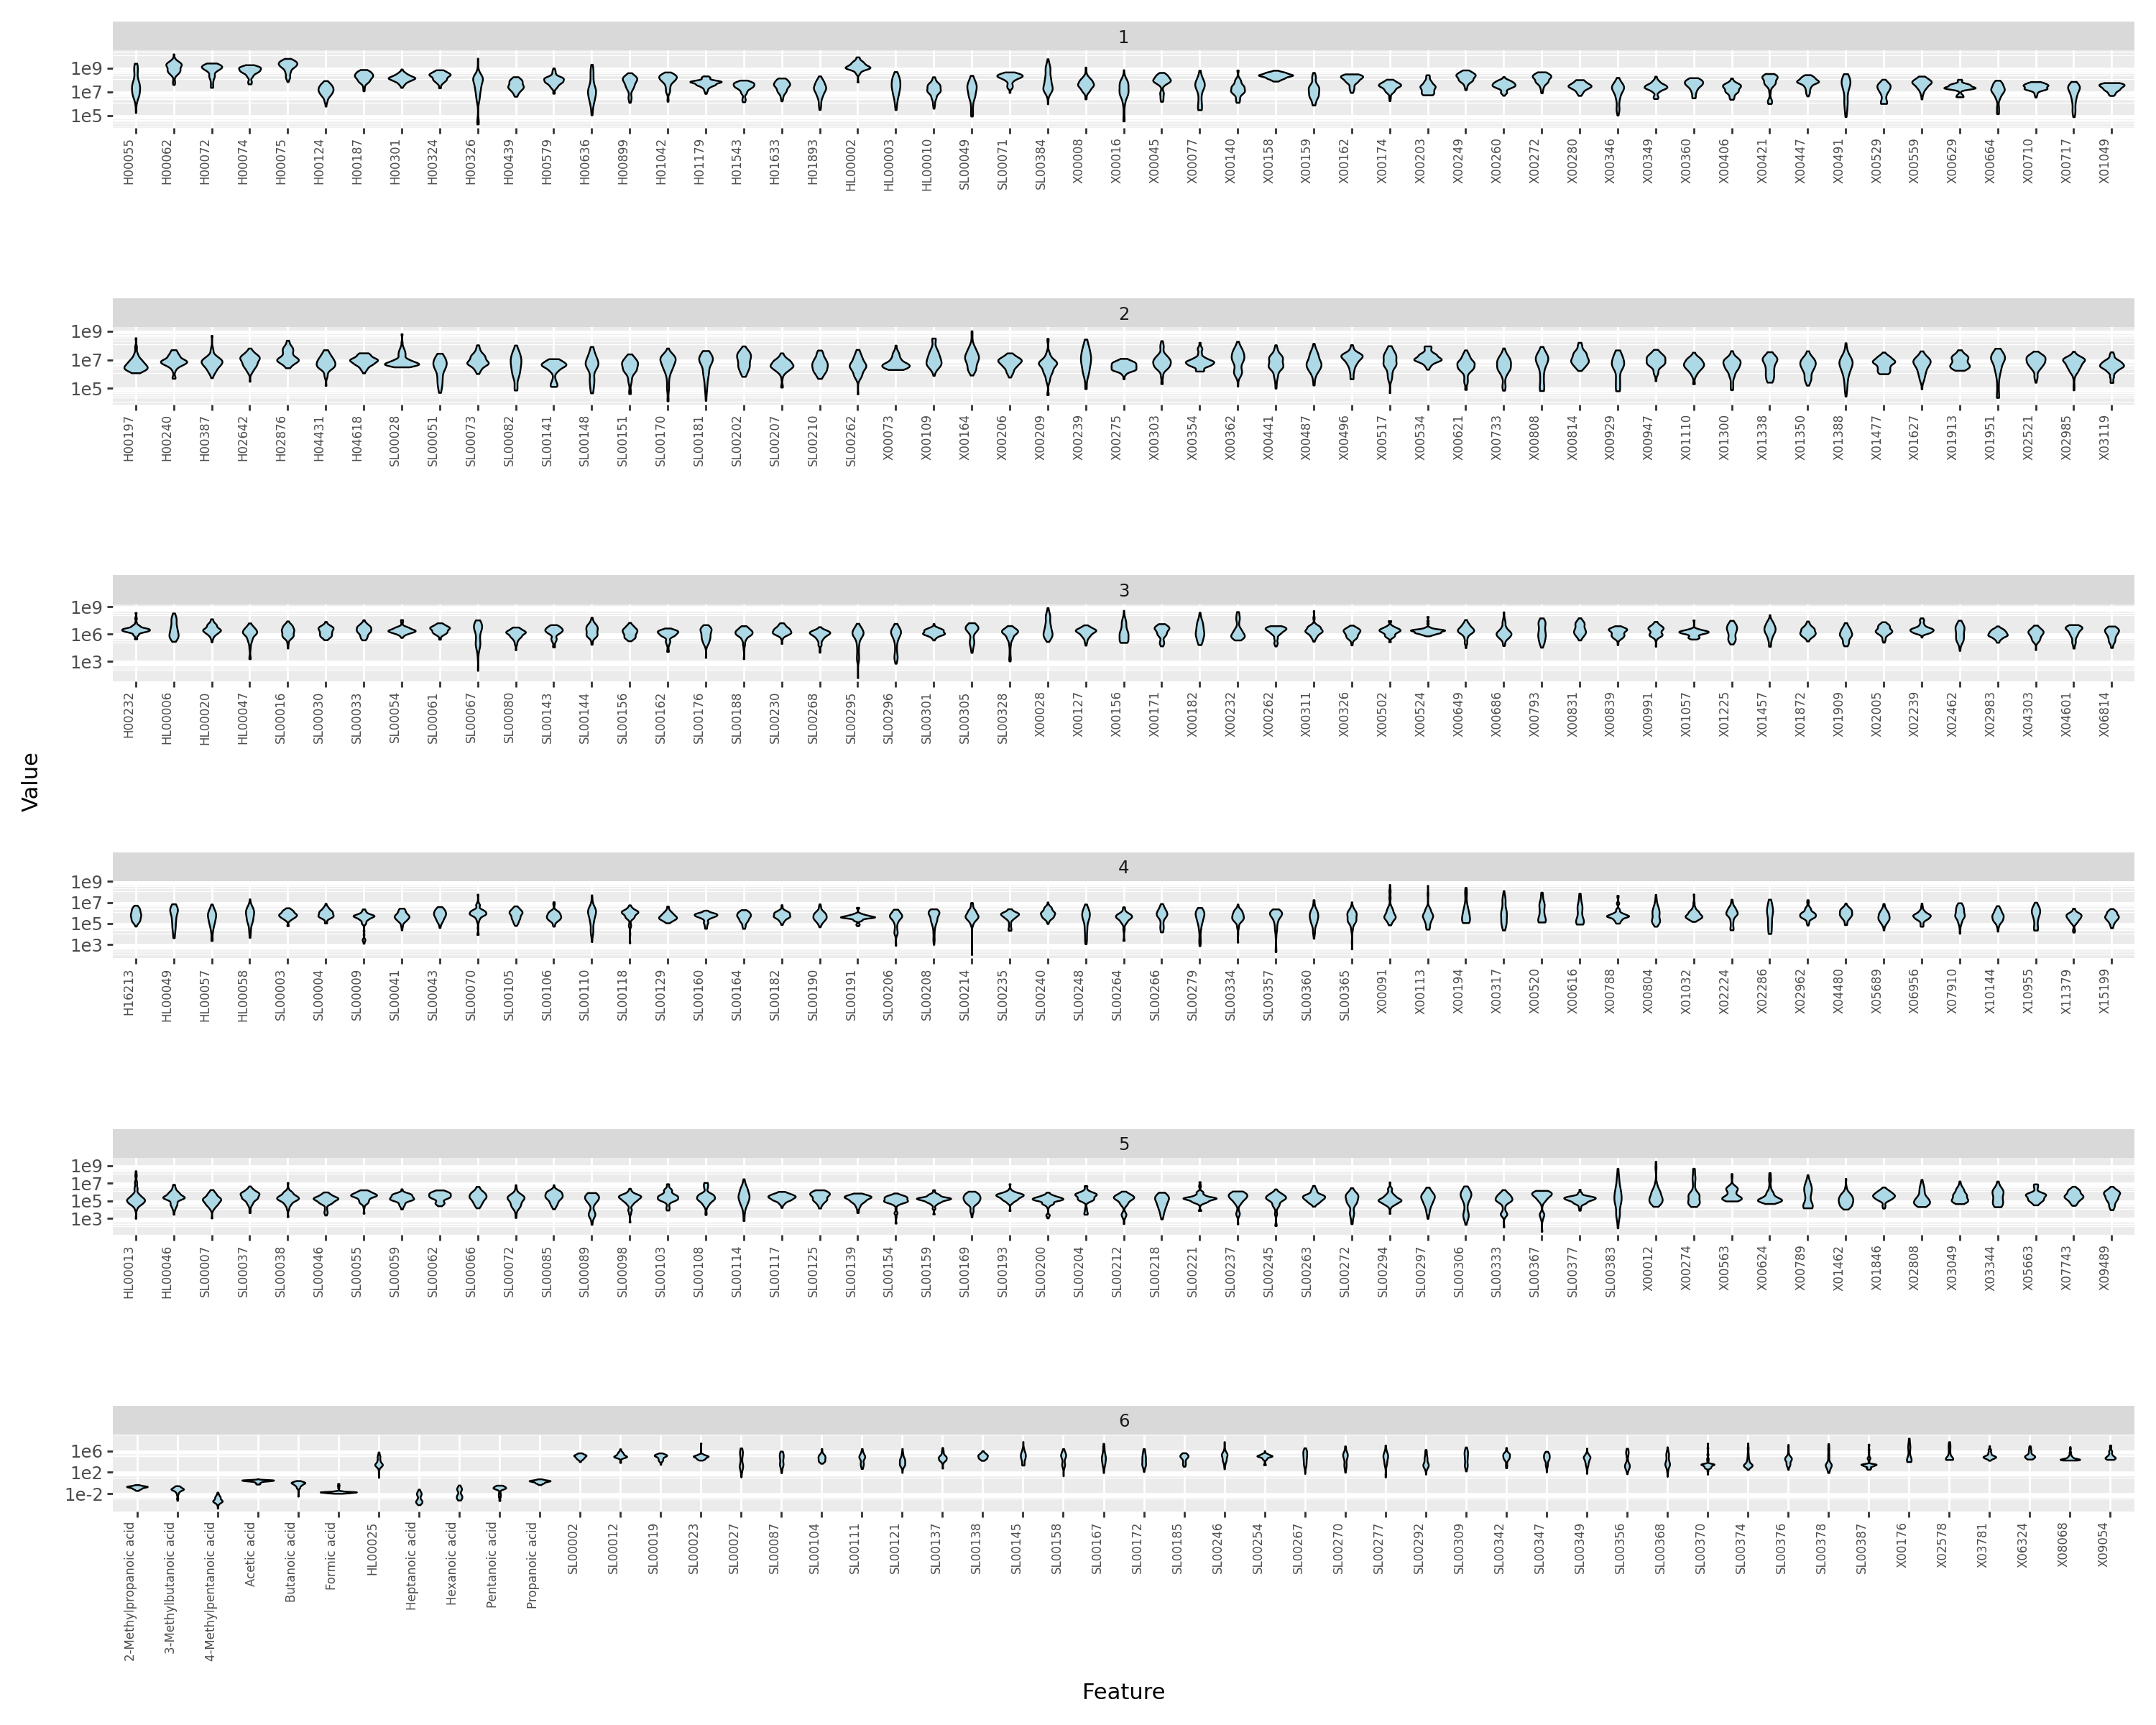

In [25]:
plot_feature_violins(merged_df)

In [28]:

def log_transform_and_scale(df):
    df_transformed = df.copy()
    numeric_cols = df_transformed.select_dtypes(include=[np.number]).columns
    df_transformed[numeric_cols] = np.log1p(df_transformed[numeric_cols])
    scaler = StandardScaler()
    df_transformed[numeric_cols] = scaler.fit_transform(df_transformed[numeric_cols])
    return df_transformed

In [ ]:
transformed_df = log_transform_and_scale(merged_df.set_index("case_number"))
transformed_df.head()
transformed_df.to_csv("metabolomics/transformed_df.csv")

C:\Users\alisa\AppData\Local\Temp\ipykernel_8072\2888183071.py:22: FutureWarning: Using print(plot) to draw and show the plot figure is deprecated and will be removed in a future version. Use plot.show().
c:\Users\alisa\AppData\Roaming\jupyter\kernels\python_alisa\.venv\lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: invalid value encountered in log10
c:\Users\alisa\AppData\Roaming\jupyter\kernels\python_alisa\.venv\lib\site-packages\plotnine\layer.py:284: PlotnineWarning: stat_ydensity : Removed 9853 rows containing non-finite values.


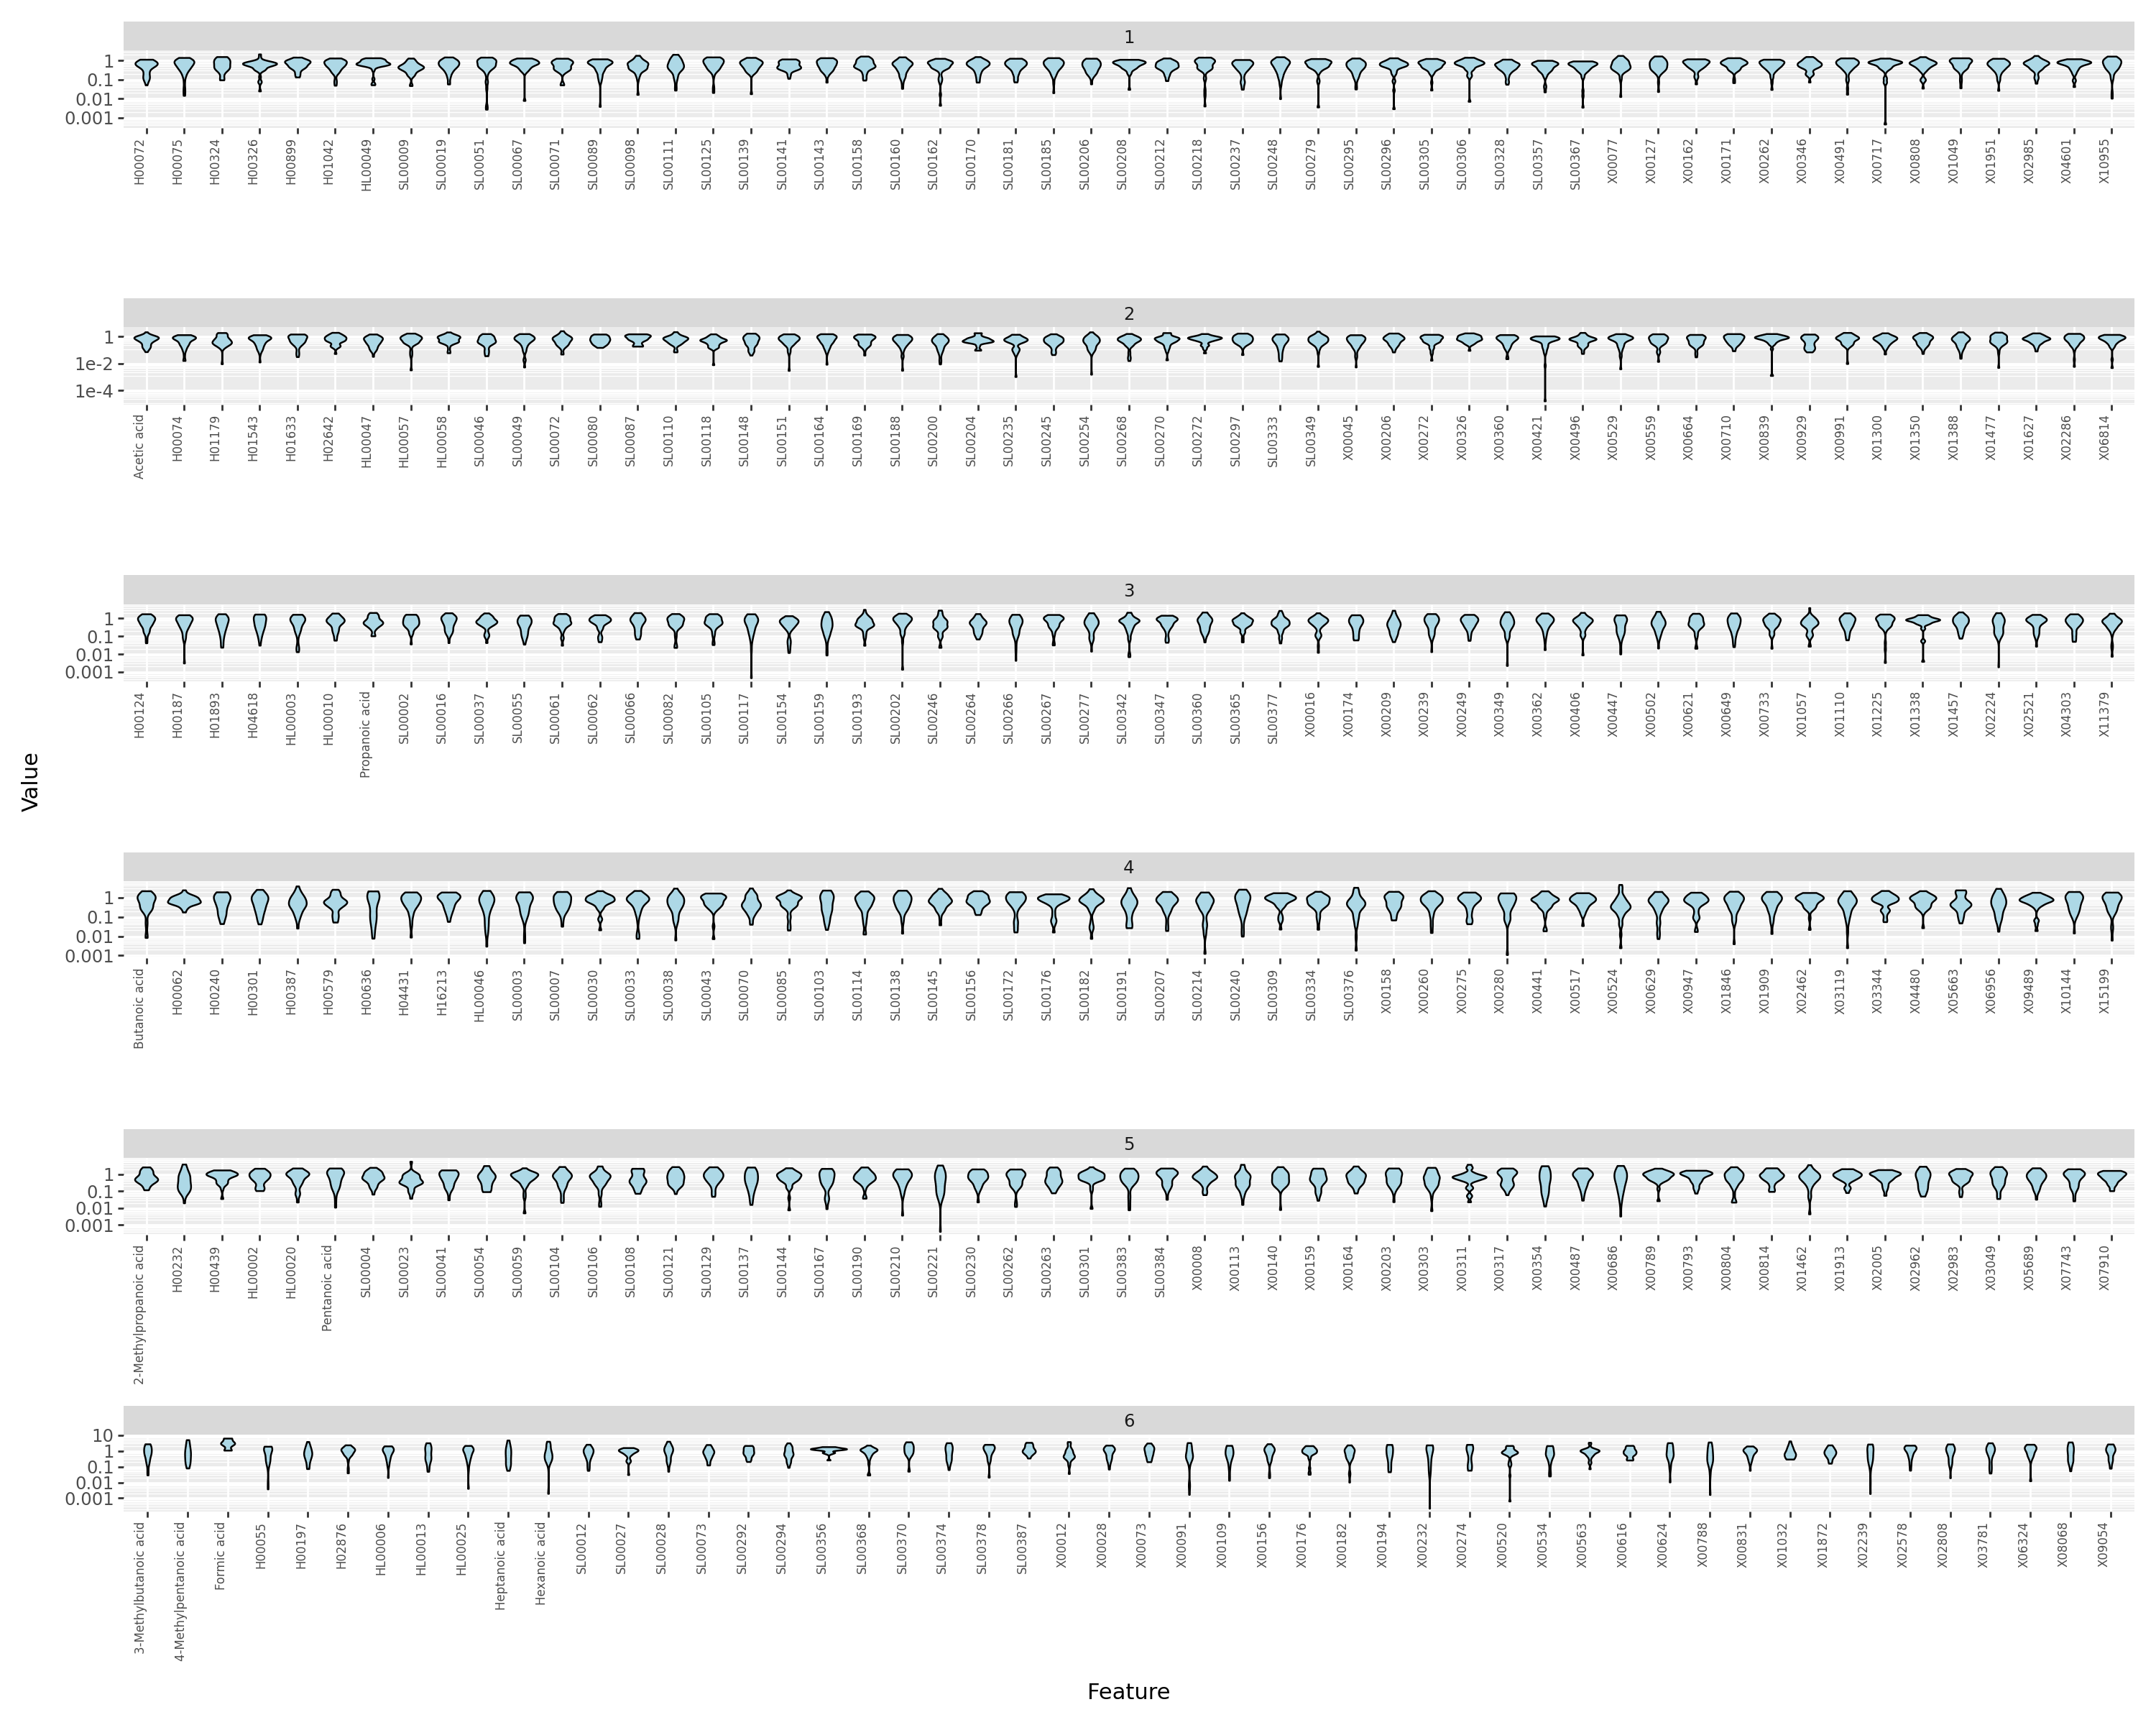

In [31]:
plot_feature_violins(transformed_df)